#### In this notebook i will use the lsm.py to see what happens to a gaussian input and the symbol that is recovvered

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

# print(sys.executable)

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 

from nonlinear.lsm import LSM
from nonlinear.solvers import KdV, Whitham
from linear.help import *


In [3]:
N = 2**8
P = 20
x = np.linspace(-P/2, P/2, N, endpoint=False)
# x = np.linspace(-3*P/4, P/4, N, endpoint=False)

g = 0.1*np.exp(-x**2)
h = np.cos(2*np.pi * x / P)



In [4]:
kdv1 = KdV(P = P, dt = 1e-3, T = 2, u0 = g, save_every=1)
# kdv1 = Whitham(P = P, dt = 1e-3, T = 5, u0 = g, save_every=1)
t,u = kdv1.splitStep()

kdv2 = KdV(P = P, dt = 1e-3, T = 2, u0 = h, save_every=1)
# kdv2 = Whitham(P = P, dt = 1e-3, T = 5, u0 = h, save_every=1)
t,u2 = kdv2.splitStep()

In [5]:
# animate_solution_nb(x, u2)

In [6]:
lsm = LSM([u2], kdv1.dt)
lsm_X = lsm.lsm()



256 256


In [7]:
half = N//2
idx = 5  #(N//2)-1 

idx_p = N//2 + idx
idx_n = N//2 - idx + 1

ell , n = lsm.fit_symbol(k = kdv1.k, idx_range = (idx_n, idx_p), deg = 5)

In [8]:
fit_table(ell, n, part="imag")

,ξ^5,ξ^4,ξ^3,ξ^2,ξ^1,ξ^0
ell,0.000860,-8.988469e-16,0.186534,1.394340e-15,-1.003252,-3.136096e-16
n,0.000923,1.198463e-16,-0.008652,-3.858198e-16,-0.496725,3.842780e-17


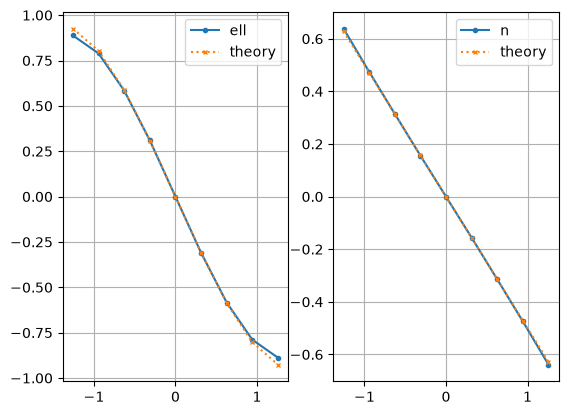

In [9]:
lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
# lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: -np.sign(k)*np.sqrt(k*np.tanh(k)), n_t = lambda k: -0.5*k)


256 256


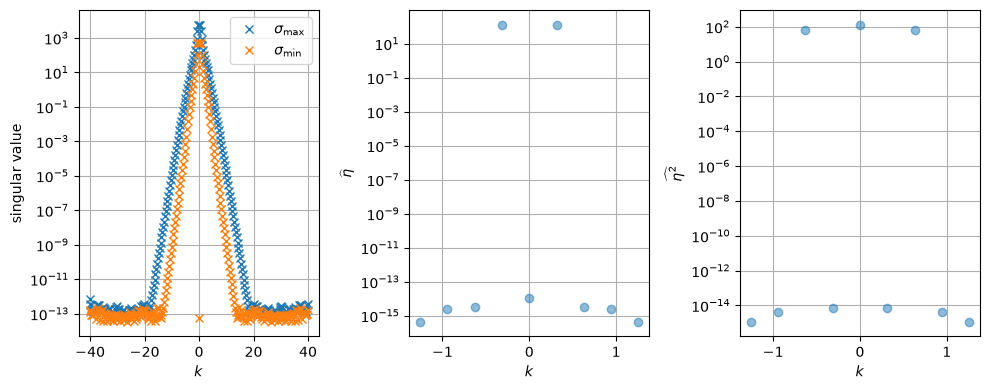

In [10]:
X = lsm.lsm()


order = np.argsort(kdv1.k)
half = kdv1.N//2
k_o = kdv1.k[order]
X_0 = X[order,0]
X_1 = X[order,1]


idx_pos = half + idx
idx_neg = half - idx + 1

# lsm.plot_symbol_fit(k, idx_range = (idx_neg, idx), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
# plt.semilogy(k, lsm.cond, 'x', color = 'r')
# plt.axvline(10, linestyle = '--')
# plt.axvline(-10, linestyle = '--')
# plt.grid(True)
# plt.xlabel("k")
# plt.ylabel(r"$\kappa(A_k)$")
# plt.show()

fig, ax = plt.subplots(1,3,figsize = (10,4))

ax[0].semilogy(kdv1.k, lsm.sigma_max, 'x', label=r'$\sigma_{\max}$')
ax[0].semilogy(kdv1.k, lsm.sigma_min, 'x', label=r'$\sigma_{\min}$')

ax[0].set_xlabel(r'$k$')
ax[0].set_ylabel('singular value')
ax[0].legend()
ax[0].grid(True)

for eta in lsm.eta_hat:
    ax[1].semilogy(k_o[idx_neg: idx_pos],np.abs(eta[0,order][idx_neg: idx_pos]), 'o', alpha = 0.5)
    ax[1].set_xlabel(r'$k$')
    ax[1].set_ylabel(r'$\widehat{\eta}$')
    # ax[1].legend()
    ax[1].grid(True)

for eta in lsm.nl_hat:
    ax[2].semilogy(k_o[idx_neg: idx_pos],np.abs(eta[0,order][idx_neg: idx_pos]), 'o', alpha = 0.5)
    ax[2].set_xlabel(r'$k$')
    ax[2].set_ylabel(r'$\widehat{\eta^2}$')
    # ax[2].legend()
    ax[2].grid(True)

plt.tight_layout()
plt.show()

In [11]:
eta = lsm.eta_hat
# animate_solution_nb(k_o[half:int(half+2*np.pi*10)],eta[-1][:,order][:,half:int(half+2*np.pi*10)].real)


In [12]:
# animate_solution_nb(k_o[half:int(half+2*np.pi*10)],eta[0][:,order][:,half:int(half+2*np.pi*10)].real)


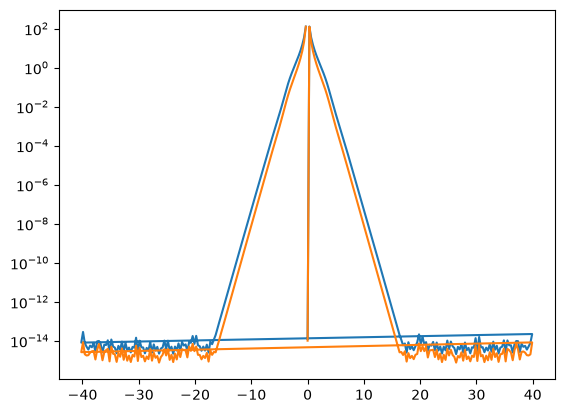

In [13]:
eta_strength = np.max(np.abs(eta[0]), axis = 0)
eta_rms      = np.sqrt(np.mean(np.abs(eta[0])**2, axis=0))

# print(eta.shape)

plt.semilogy(kdv1.k,eta_strength)
plt.semilogy(kdv1.k,eta_rms)
# plt.semilogy(kdv1.k , np.exp(-np.e*(np.abs(kdv1.k)))) # The modes are decaying like exp(-a|k|)
